# Global Food Delivery Market — Exploratory Data Analysis (EDA)

## 1. Project Overview

### Introduction

This project focuses on exploring and analyzing a global food delivery dataset containing 8,000 orders across multiple metropolitan cities, restaurant categories, and ordering channels.

The purpose of this analysis is to identify patterns in customer behavior, delivery performance, customer satisfaction, and restaurant profitability.

### Objectives

The main objectives of this project are:

- Understand the structure and characteristics of the dataset.
- Assess data quality and identify potential inconsistencies.
- Explore order value, discounts, and restaurant profitability.
- Analyze delivery performance and its relationship with customer satisfaction.
- Investigate differences across cities, cuisine categories, and ordering channels.
- Identify meaningful patterns and derive actionable business insights.

### Dataset

The dataset contains 8,000 observations and 26 features, covering order information, restaurant characteristics, delivery metrics, customer ratings, and derived business indicators.

### Key Questions

1. Which factors are associated with higher customer satisfaction?
2. How do delivery distance and delivery time relate to customer ratings?
3. How do discounts affect order value and estimated restaurant margins?
4. Are there differences in ordering behavior across cities and cuisine categories?
5. How does ordering channel influence delivery performance?

## 2. Imports & Loading Data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [3]:
df=pd.read_csv('../data/global_food_delivery.csv')

## 3. Initial Data Exploration
We examine:
- The first observations using head().
- The dataset dimensions using shape.
- Column names and data types using info().
- Numerical statistics using describe().
- Categorical distributions using describe(include='str').
- The number of unique values in each column using nunique().

In [4]:
df.head()

,order_id,metro_city,cuisine_category,order_channel,order_value_usd,discount_applied_usd,delivery_distance_km,estimated_prep_time_min,actual_delivery_time_min,delivery_fee_usd,...,delivery_speed_km_per_hr,total_fulfillment_time_min,delivery_fee_ratio,customer_spending_tier,logistics_friction_index,estimated_restaurant_net_margin_usd,customer_satisfaction_tier,primary_satisfaction_driver,cot_market_dynamics_rationale,confidence_score
0,ord_02fb1f942abf,Berlin,Burgers & Fast Food,Online Delivery App,20.80,0.00,0.5,14,8.0,2.02,...,3.75,22.0,0.0971,Budget-Saver,0.20,6.20,Neutral-Tolerant-3Star,Rapid-Fulfillment,Pesanan 'ord_02fb1f942abf' di metropolis 'Berl...,0.986
1,ord_0337e00c92a2,Berlin,Burgers & Fast Food,Online Delivery App,3.50,1.20,0.9,24,8.0,3.31,...,6.75,32.0,0.9457,Occasional-Promo-Seeker,4.18,-0.21,Satisfied-4Star,High-Value-Discounting,Pesanan 'ord_0337e00c92a2' di metropolis 'Berl...,0.988
2,ord_0384f1e25fed,Berlin,Burgers & Fast Food,Takeaway / Pickup,13.12,1.46,0.0,13,0.0,0.00,...,0.00,13.0,0.0000,Budget-Saver,0.20,4.31,Neutral-Tolerant-3Star,Rapid-Fulfillment,Pesanan 'ord_0384f1e25fed' di metropolis 'Berl...,0.986
3,ord_0406c3fd20e4,Berlin,Burgers & Fast Food,Takeaway / Pickup,10.54,1.32,0.0,15,0.0,0.00,...,0.00,15.0,0.0000,Budget-Saver,1.50,3.23,Delighted-5Star,Rapid-Fulfillment,Pesanan 'ord_0406c3fd20e4' di metropolis 'Berl...,0.989
4,ord_059fca6f1251,Berlin,Burgers & Fast Food,Online Delivery App,121.46,9.06,0.8,15,8.0,3.02,...,6.00,23.0,0.0249,High-Roller-Gourmet,3.94,43.44,Satisfied-4Star,Rapid-Fulfillment,Pesanan 'ord_059fca6f1251' di metropolis 'Berl...,0.989


In [5]:
df.shape

(8000, 26)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 26 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_id                             8000 non-null   str    
 1   metro_city                           8000 non-null   str    
 2   cuisine_category                     8000 non-null   str    
 3   order_channel                        8000 non-null   str    
 4   order_value_usd                      8000 non-null   float64
 5   discount_applied_usd                 8000 non-null   float64
 6   delivery_distance_km                 8000 non-null   float64
 7   estimated_prep_time_min              8000 non-null   int64  
 8   actual_delivery_time_min             8000 non-null   float64
 9   delivery_fee_usd                     8000 non-null   float64
 10  customer_rating                      8000 non-null   float64
 11  restaurant_price_tier                8000

In [7]:
df.describe()

,order_value_usd,discount_applied_usd,delivery_distance_km,estimated_prep_time_min,actual_delivery_time_min,delivery_fee_usd,customer_rating,net_effective_order_price,discount_percentage,delivery_speed_km_per_hr,total_fulfillment_time_min,delivery_fee_ratio,logistics_friction_index,estimated_restaurant_net_margin_usd,confidence_score
count,8000.000000,8000.000000,8000.000000,8000.00000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,30.222839,3.328607,3.048638,18.04200,11.272588,2.962597,4.281375,29.856829,11.911265,10.287050,29.314588,0.184009,2.251100,10.789798,0.987976
std,26.366910,5.183003,3.937749,6.76934,13.533084,2.672989,0.647210,24.372821,12.115306,9.335752,16.210216,0.270723,1.624059,10.667783,0.002500
min,3.500000,0.000000,0.000000,5.00000,0.000000,0.000000,1.000000,2.300000,0.000000,0.000000,5.000000,0.000000,0.200000,-0.210000,0.953000
25%,12.920000,0.000000,0.000000,13.00000,0.000000,0.000000,4.000000,14.040000,0.000000,0.000000,18.000000,0.000000,0.850000,3.727500,0.988000
50%,21.705000,1.530000,1.600000,18.00000,8.000000,2.970000,4.500000,22.310000,9.535000,10.500000,26.000000,0.100850,2.190000,7.440000,0.989000
75%,37.892500,4.440000,4.500000,22.00000,15.200000,4.540000,5.000000,37.235000,23.022500,17.050000,36.700000,0.249425,3.300000,13.912500,0.989000
max,145.000000,35.000000,22.000000,49.00000,75.000000,9.500000,5.000000,154.500000,35.020000,57.000000,111.000000,2.714300,8.920000,67.850000,0.990000


In [8]:
df.describe(include='str')

,order_id,metro_city,cuisine_category,order_channel,restaurant_price_tier,weather_condition,customer_spending_tier,customer_satisfaction_tier,primary_satisfaction_driver,cot_market_dynamics_rationale
count,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000
unique,8000,12,7,3,3,4,4,4,5,8000
top,ord_02fb1f942abf,New York,Burgers & Fast Food,Online Delivery App,$$ Moderate,Clear,Budget-Saver,Satisfied-4Star,Rapid-Fulfillment,Pesanan 'ord_02fb1f942abf' di metropolis 'Berl...
freq,1,1010,1788,5255,3469,4364,3479,4071,3184,1


In [9]:
df.nunique()

order_id                               8000
metro_city                               12
cuisine_category                          7
order_channel                             3
order_value_usd                        4323
discount_applied_usd                   1343
delivery_distance_km                    202
estimated_prep_time_min                  41
actual_delivery_time_min                515
delivery_fee_usd                        426
customer_rating                           9
restaurant_price_tier                     3
is_peak_hour                              2
weather_condition                         4
net_effective_order_price              4348
discount_percentage                    2414
delivery_speed_km_per_hr               1650
total_fulfillment_time_min              681
delivery_fee_ratio                     3395
customer_spending_tier                    4
logistics_friction_index                674
estimated_restaurant_net_margin_usd    2685
customer_satisfaction_tier      

### Initial Observations

- The dataset contains 8000 rows and 26 columns.
- No missing values were detected.
- The dataset contains numerical, categorical and boolean variables.
- The most frequent delivery channel is Online Delivery App
- Customer ratings are generally high, with a median rating of 4.5
- Some delivery related variables such as delivery_distance_km, actual_delivery_time_min ect. contain zero values, which may be associated with non-delivery ordering channels.
- Some numerical variables such as order_value_usd, discount_applied_usd, delivery_distance_km etc. show difference between their mean and median, suggesting potentially skewed distributions.

## 4. Data Quality Assessment

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df['order_id'].duplicated().sum()

np.int64(0)

In [12]:
price_check = np.isclose(
    df["net_effective_order_price"],
    df["order_value_usd"] - df["discount_applied_usd"] + df["delivery_fee_usd"]
)
price_check.all()


np.True_

In [13]:
time_check = np.isclose(
    df["total_fulfillment_time_min"],
    df["estimated_prep_time_min"] + df["actual_delivery_time_min"]
)
time_check.all()

np.True_

In [14]:
df.groupby("order_channel")[
    ["delivery_distance_km", "actual_delivery_time_min", "delivery_fee_usd"]
].agg(["min", "median", "max"])

delivery_distance_km               \
                                     min median   max   
order_channel                                           
Dine-In POS                          0.0    0.0   0.0   
Online Delivery App                  0.5    3.4  22.0   
Takeaway / Pickup                    0.0    0.0   0.0   

                    actual_delivery_time_min              delivery_fee_usd  \
                                         min median   max              min   
order_channel                                                                
Dine-In POS                              0.0    0.0   0.0             0.00   
Online Delivery App                      8.0   11.6  75.0             2.02   
Takeaway / Pickup                        0.0    0.0   0.0             0.00   

                                 
                    median  max  
order_channel                    
Dine-In POS           0.00  0.0  
Online Delivery App   3.94  9.5  
Takeaway / Pickup     0.00  0.0


### Duplicate Values
The dataset contains no duplicate rows, and the order_id column contains no duplicate identifiers.

### Derived Features
- `net_effective_order_price `is calculated as the order value minus the applied discount plus the delivery fee.
- `total_fulfillment_time_min` is calculated as the estimated preparation time plus the actual delivery time.
- `discount_percentage` represents `(discount_applied_usd / order_value_usd) * 100`.
- `delivery_fee_ratio` represents `delivery_fee_usd / order_value_usd`.
- `delivery_speed_km_per_hr` is derived from `delivery_distance_km / (actual_delivery_time_min / 60)` for delivery orders (and `0.0` for non-delivery orders).
- A small subset of orders shows a slightly negative `estimated_restaurant_net_margin_usd` (down to `-$0.21`), which is valid and occurs when heavy promotional discounts are applied to very low-value orders.

### Zero-Value Validation (Delivery Metrics)

- All zero values in `delivery_distance_km`, `actual_delivery_time_min`, and `delivery_fee_usd` belong strictly to non-delivery channels (`Dine-In POS` and `Takeaway / Pickup`), where `min`, `median`, and `max` are all `0.0`.
- Orders placed via `Online Delivery App` always have positive values (`delivery_distance_km` from `0.5` to `22.0` km, `actual_delivery_time_min` from `8.0` to `75.0` min, and `delivery_fee_usd` from `$2.02` to `$9.50`), confirming that the zeros are structurally valid rather than missing or erroneous entries.

## 5. Univariate Analysis

In [15]:
numerical = [
    "order_value_usd",
    "discount_applied_usd",
    "delivery_distance_km",
    "estimated_prep_time_min",
    "actual_delivery_time_min",
    "delivery_fee_usd",
    "customer_rating"
]

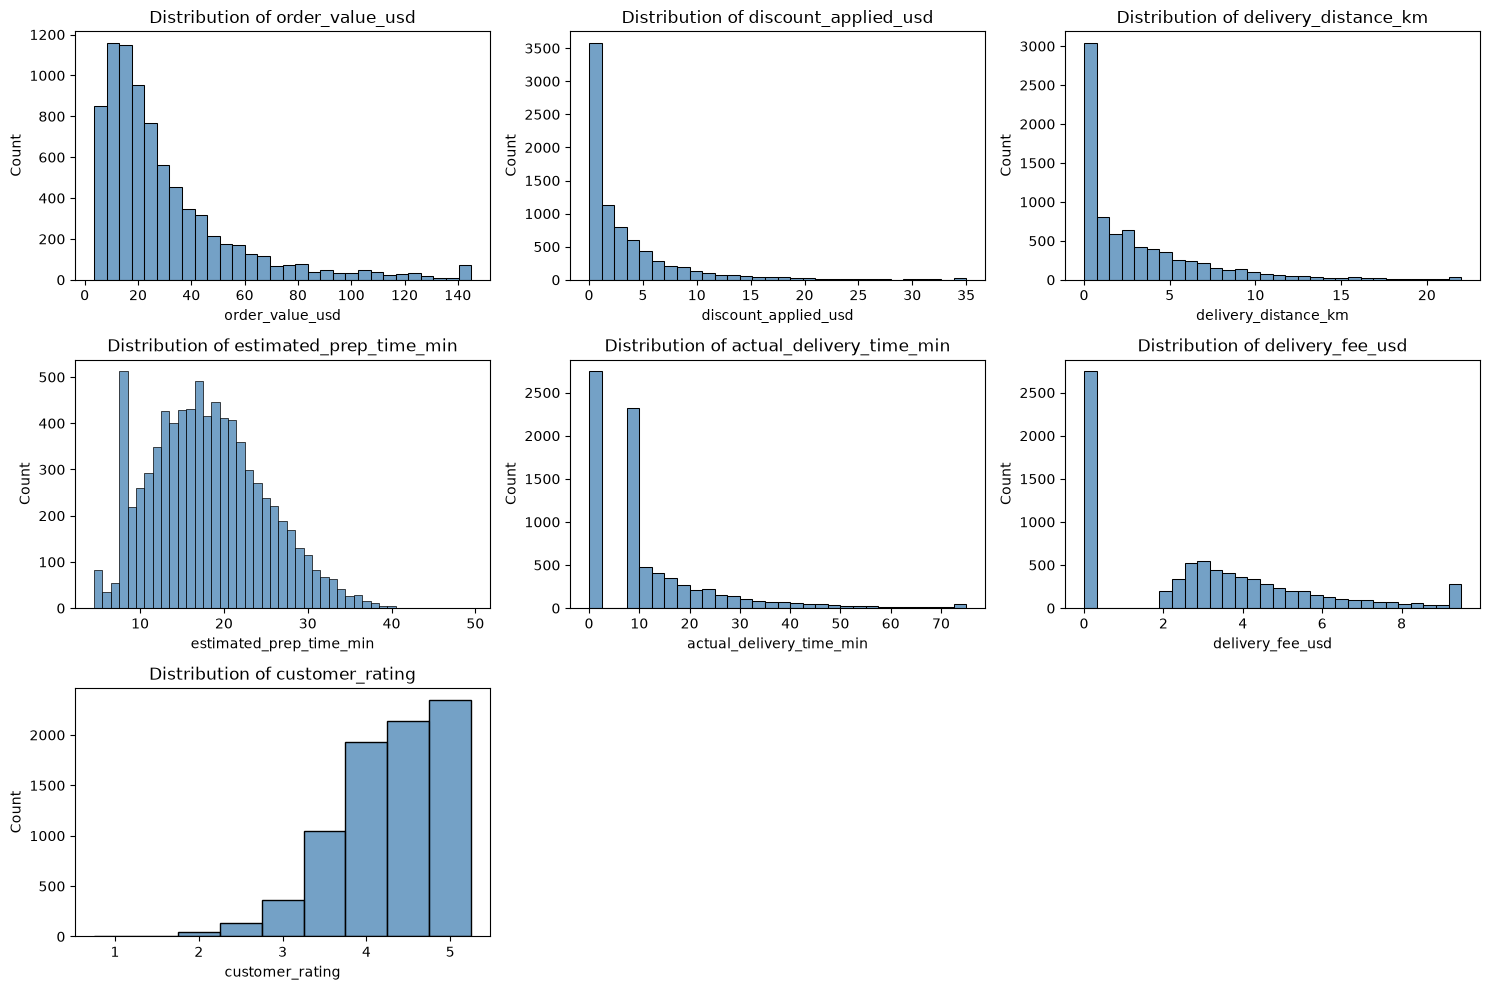

In [16]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(numerical):
    if col == "estimated_prep_time_min":
    
        sns.histplot(df[col], discrete=True, ax=axes[i], color="steelblue")
    elif col == "customer_rating":
        sns.histplot(
            df[col], bins=np.arange(0.75, 5.5, 0.5), ax=axes[i], color="steelblue"
        )
    else:
        sns.histplot(df[col], bins=30, ax=axes[i], color="steelblue")

    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")

for j in range(len(numerical), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [20]:
df.skew(numeric_only=True)

order_value_usd                        2.019882
discount_applied_usd                   2.844169
delivery_distance_km                   1.889647
estimated_prep_time_min                0.401232
actual_delivery_time_min               1.990362
delivery_fee_usd                       0.565250
customer_rating                       -0.789576
is_peak_hour                           0.344564
net_effective_order_price              2.105149
discount_percentage                    0.422069
delivery_speed_km_per_hr               0.471828
total_fulfillment_time_min             1.468040
delivery_fee_ratio                     3.228182
logistics_friction_index               0.695778
estimated_restaurant_net_margin_usd    2.062834
confidence_score                      -6.320110
dtype: float64

### Observations on Numerical Distributions

- **Right-Skewed Distributions:** `order_value_usd`, `discount_applied_usd`, `delivery_distance_km`, and `actual_delivery_time_min` are right-skewed, with most orders concentrated at lower values and a long tail of high-value or long-distance orders.
- **Zero-Inflation in Delivery Metrics:** `delivery_distance_km`, `actual_delivery_time_min`, and `delivery_fee_usd` show a prominent spike at `0`, representing non-delivery orders (e.g., Takeaway / Pickup).
- **Left-Skewed Ratings:** `customer_rating` is left-skewed, with the majority of ratings clustered between `4.0` and `5.0`.
- **Upper-Bound Capping:** Small spikes at the upper limits of `order_value_usd` (`$145`), `discount_applied_usd` (`$35`), and `delivery_fee_usd` (`$9.50`) indicate that these metrics are capped at fixed maximum thresholds.

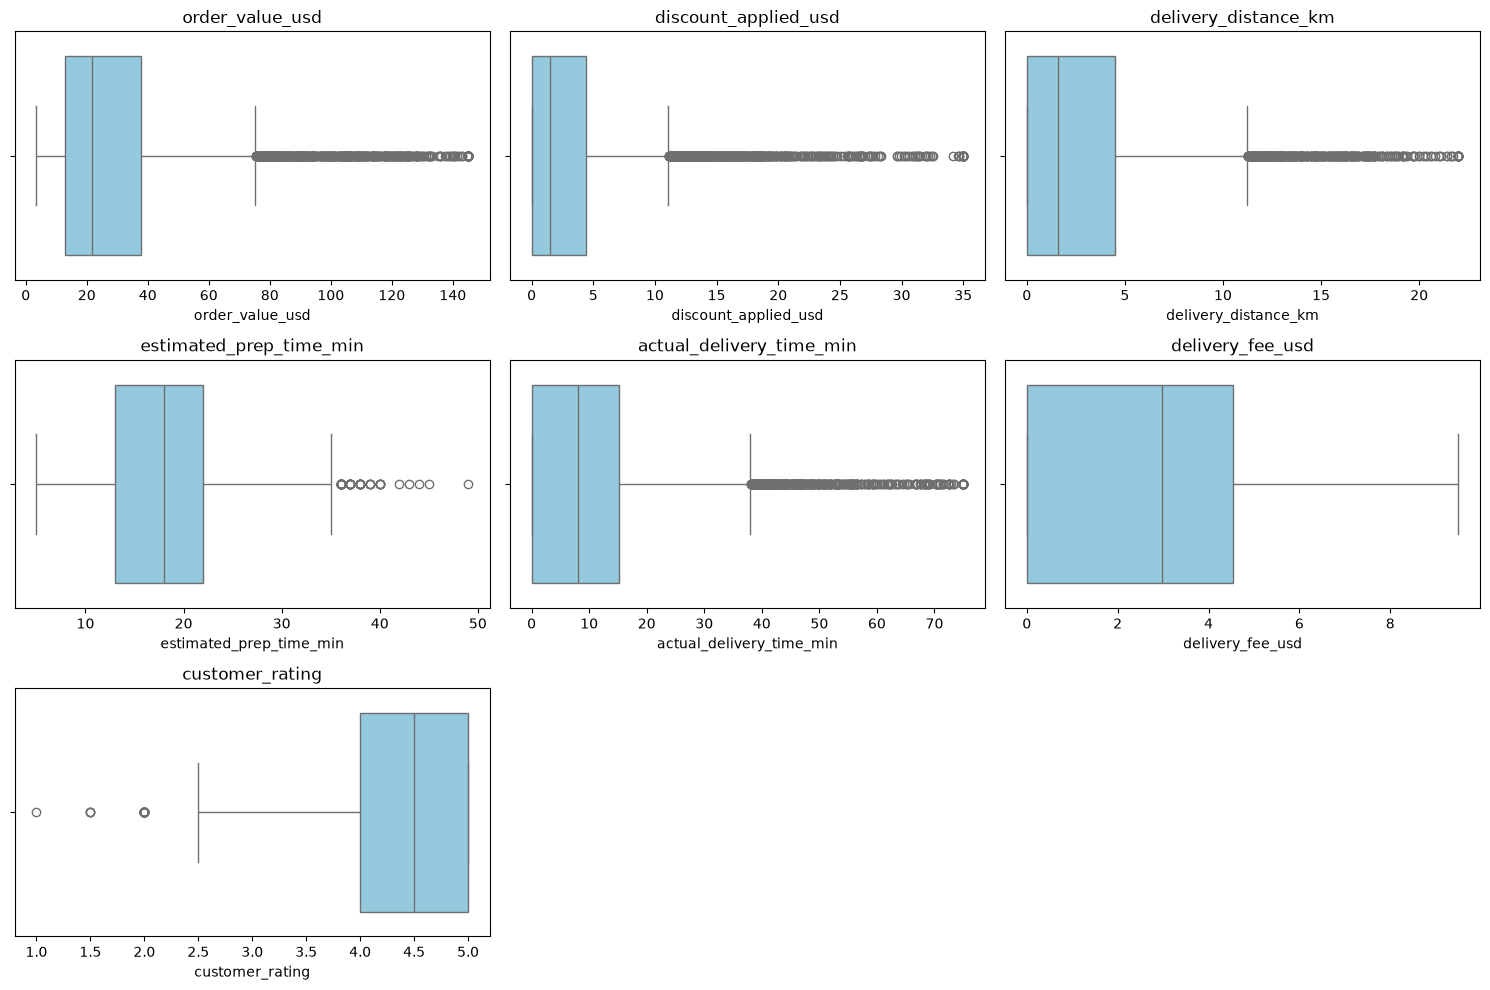

In [17]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(numerical):
    sns.boxplot(x=df[col], ax=axes[i], color='skyblue')
    axes[i].set_title(col)

for j in range(len(numerical), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Observations on Outliers (Boxplots)

- **Right-Tail Outliers in Order & Delivery Metrics:** `order_value_usd` (above ~$75), `discount_applied_usd` (above ~$11), `delivery_distance_km` (above ~11 km), and `actual_delivery_time_min` (above ~38 min) contain numerous upper outliers. These represent legitimate large group orders, high-value promos, and long-distance deliveries rather than data entry errors.
- **Zero-Anchored Quartiles:** For `discount_applied_usd`, `delivery_distance_km`, `actual_delivery_time_min`, and `delivery_fee_usd`, the 25th percentile (`Q1`) lies at `0` due to non-discounted and non-delivery orders.
- **No Outliers in `delivery_fee_usd`:** Because `Q1 = $0.00` widens the interquartile range (IQR), the upper whisker extends all the way to the `$9.50` cap without flagging any statistical outliers.
- **Well-Behaved Prep Time:** `estimated_prep_time_min` shows a compact, symmetric box centered at 18 minutes with only a few mild outliers above 35 minutes (up to 49 minutes).
- **Low-Rating Outliers:** `customer_rating` has its interquartile range tightly concentrated between `4.0` and `5.0`, flagging ratings of `1.0`, `1.5`, and `2.0` as low-end outliers.

In [18]:
categorical = [
    "metro_city",
    "cuisine_category",
    "order_channel",
    "restaurant_price_tier",
    "weather_condition",
    "customer_satisfaction_tier",
]


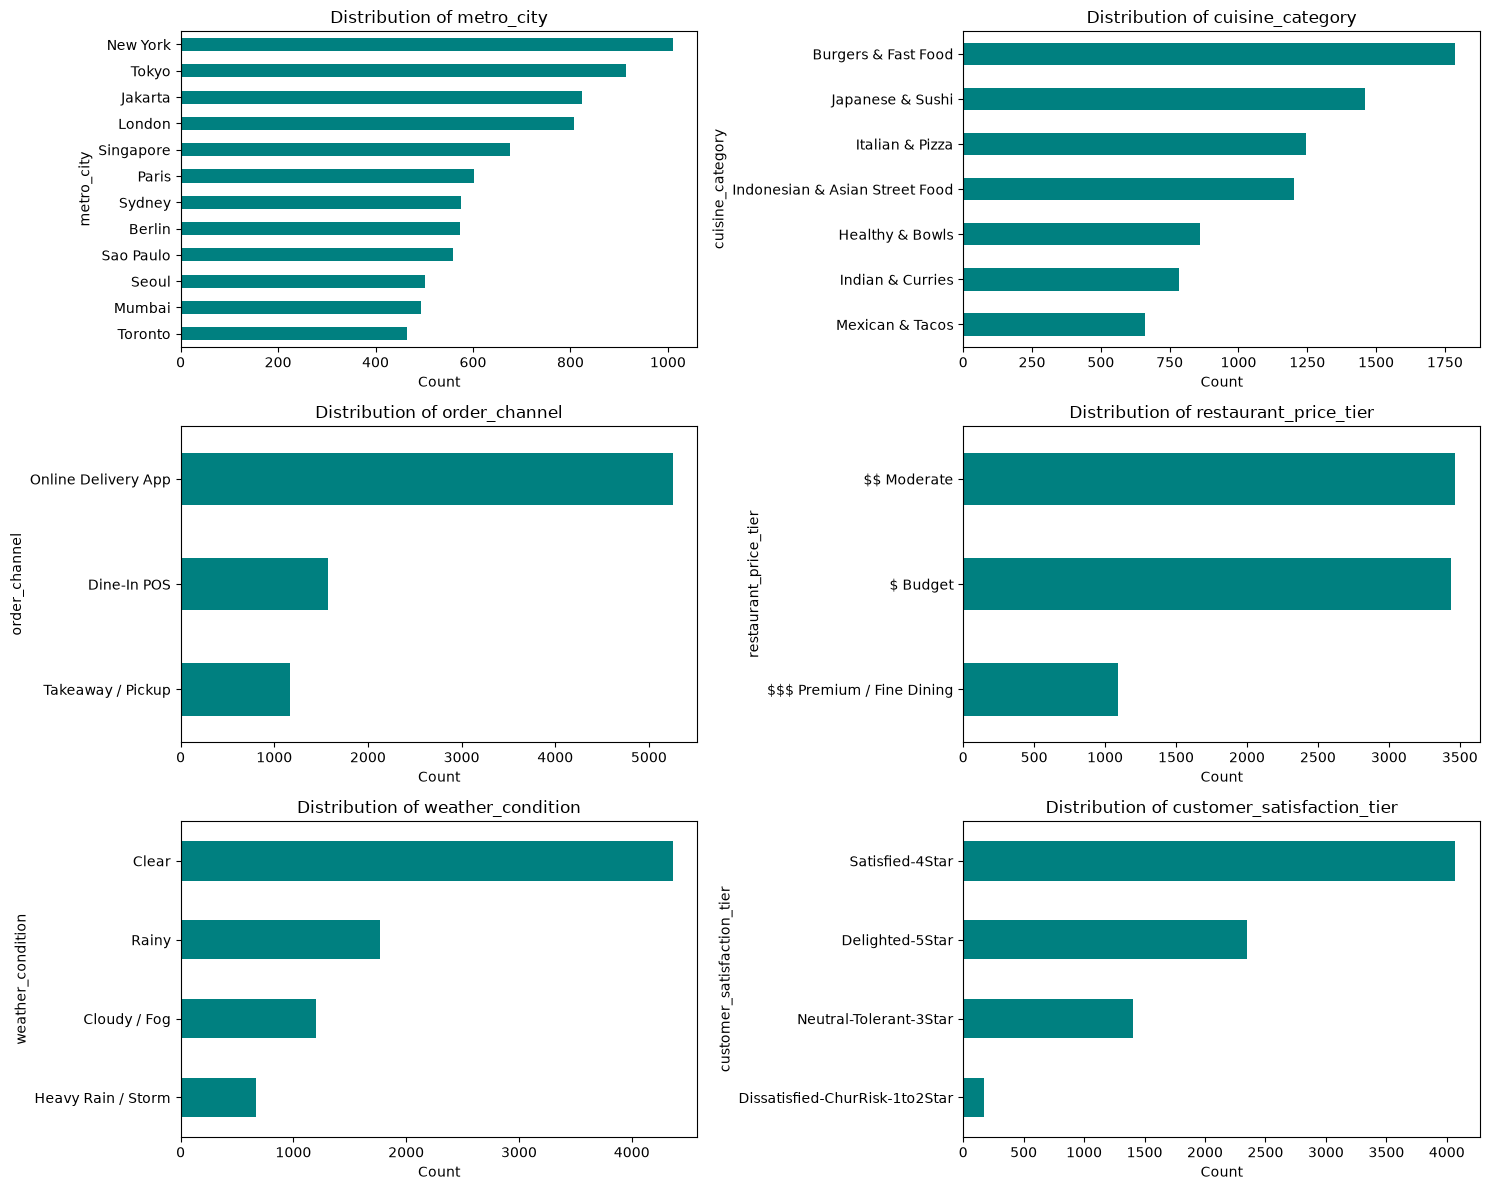

In [19]:
plt.rcParams["text.parse_math"] = False

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(categorical):
    df[col].value_counts().plot(kind="barh", ax=axes[i], color="teal")
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel("Count")
    axes[i].invert_yaxis()

plt.tight_layout()
plt.show()

### Observations on Categorical Distributions

- **Geographic Spread (`metro_city`):** Orders are distributed across 12 global metropolitan cities, led by **New York** (1,010 orders), followed by **Tokyo**, **Jakarta**, and **London** (~800–910 orders each), while **Toronto** has the lowest volume (~460 orders).
- **Cuisine Preferences (`cuisine_category`):** **Burgers & Fast Food** is the most popular category (1,788 orders), followed by **Japanese & Sushi** (~1,460) and **Italian & Pizza** (~1,250), whereas **Mexican & Tacos** is the least frequent (~660).
- **Channel Dominance (`order_channel`):** **Online Delivery App** accounts for roughly two-thirds of all orders (5,255 orders / 65.7%), while **Dine-In POS** (~1,570) and **Takeaway / Pickup** (~1,175) make up the remaining third.
- **Price Tier Concentration (`restaurant_price_tier`):** **$$ Moderate** (3,469 orders) and **$ Budget** (~3,430 orders) represent over 86% of total volume, while **$$$ Premium / Fine Dining** accounts for ~14% (~1,100 orders).
- **Weather Conditions (`weather_condition`):** More than half of all orders take place in **Clear** weather (4,364 orders / 54.6%), with **Rainy** (~1,750), **Cloudy / Fog** (~1,200), and **Heavy Rain / Storm** (~680) making up the rest.
- **Customer Satisfaction (`customer_satisfaction_tier`):** Over 80% of customers fall into positive tiers—**Satisfied-4Star** (4,071 orders / 50.9%) and **Delighted-5Star** (~2,340 orders / 29.3%)—while **Dissatisfied-ChurRisk-1to2Star** represents a small fraction (~2.4%).

## 6. Bivariate & Multivariate Analysis

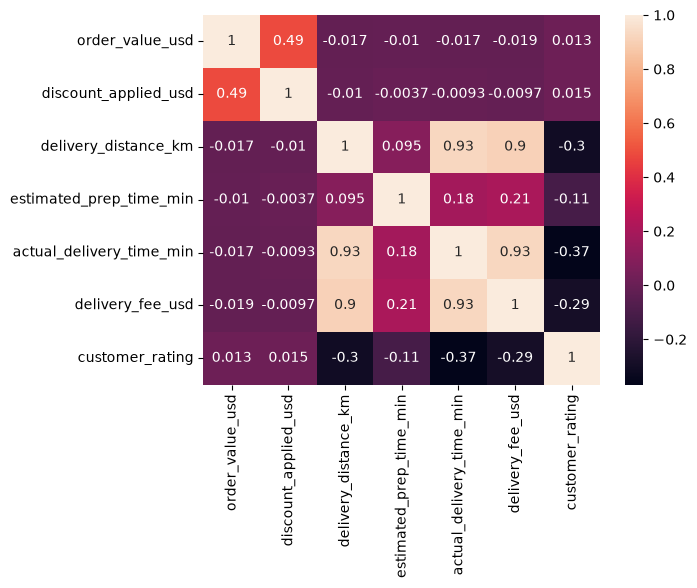

In [24]:
sns.heatmap(df[numerical].corr(numeric_only=True), annot=True)
plt.show()

### Observations on Numerical Correlations

- **Strong Logistics Cluster (`r = 0.90` to `0.93`):** `delivery_distance_km`, `actual_delivery_time_min`, and `delivery_fee_usd` are tightly correlated with one another. Longer distances directly drive higher delivery times (`r = 0.93`) and higher delivery fees (`r = 0.90`), though these coefficients are partially amplified by the zero-inflated non-delivery orders.
- **Order Size & Discounts (`r = 0.49`):** `order_value_usd` shows a moderate positive correlation with `discount_applied_usd`, indicating that higher-value orders receive larger absolute discounts, while remaining independent of delivery distance or transit time (`r ≈ -0.02`).
- **Primary Negative Drivers of `customer_rating`:** `actual_delivery_time_min` has the strongest negative correlation with ratings (`r = -0.37`), followed by `delivery_distance_km` (`r = -0.30`) and `delivery_fee_usd` (`r = -0.29`). By contrast, `estimated_prep_time_min` has a much weaker negative effect (`r = -0.11`).